## UCS420 Lab Assignment 9 - NLP Text Preprocessing
By Gurkirpa Singh, 3Q34, 1024170378

In [1]:
ROLL_NO = 1024170378          # <-- your full roll number
NAME = "Gurkirpa Singh"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [2]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [3]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170378   Name: Gurkirpa Singh   Fingerprint: 39EE2FDA   Tickets: 15

Ticket_ID                                                                             Ticket_Text
      T01                                               The VPN is showing an error. Please help.
      T02               Server is showing an error during the lab. The same problem occurs again.
      T03                                  The printer was working yesterday. Can you check this?
      T04 I keep getting logged out of the projector on my laptop. The same problem occurs again.
      T05                             Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it.
      T06                                               The printer won't print; it isn't jammed.
      T07                   I was locked out of the VPN after restarting the system. Please help.
      T08      Printer stopped responding after resetting my password. I don't know what changed.
      T09              Projector

---
## Q1. Preprocessing pipeline
Run `process_ticket()` on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [4]:
# Q1
rows = []
res = {}
for tid, text in zip(df.Ticket_ID, df.Ticket_Text):
    r = process_ticket(text)
    res[tid] = r
    rows.append([tid, len(r["sentences"]), len(r["tokens"]), len(r["punct"]),
                 len(r["stops"]), len(set(r["tokens"])), len(r["final"])])

q1 = pd.DataFrame(rows, columns=["Ticket", "Sentences", "Tokens", "Punct", "Stopwords", "Unique", "Final"])
q1.loc[len(q1)] = ["TOTAL"] + q1.iloc[:, 1:].sum().tolist()
print(q1.to_string(index=False))

Ticket  Sentences  Tokens  Punct  Stopwords  Unique  Final
   T01          2      10      2          3       9      5
   T02          2      15      2          7      13      6
   T03          2      11      2          5      11      4
   T04          2      18      2          9      16      7
   T05          1       9      2          2       9      5
   T06          1      11      2          3      10      6
   T07          2      15      2          7      13      6
   T08          2      15      2          5      14      8
   T09          2      13      2          4      12      7
   T10          2      14      2          5      13      7
   T11          2      15      2          6      14      7
   T12          1       7      2          2       7      3
   T13          2      11      2          2      10      7
   T14          2      12      2          5      12      5
   T15          1       8      3          2       7      3
 TOTAL         26     184     31         67     170     

In [5]:
# tokens of the focus tickets
for tid in FOCUS:
    r = res[tid]
    print(tid, ":", df.loc[df.Ticket_ID == tid, "Ticket_Text"].item())
    print("tokens :", r["tokens"])
    print("punct  :", r["punct"])
    print("stops  :", r["stops"])
    print("final  :", r["final"])
    print()

T06 : The printer won't print; it isn't jammed.
tokens : ['the', 'printer', 'wo', "n't", 'print', ';', 'it', 'is', "n't", 'jammed', '.']
punct  : [';', '.']
stops  : ['the', 'it', 'is']
final  : ['printer', 'wo', "n't", 'print', "n't", 'jammed']

T11 : I reinstalled the wifi after resetting my password. It works on another computer.
tokens : ['i', 'reinstalled', 'the', 'wifi', 'after', 'resetting', 'my', 'password', '.', 'it', 'works', 'on', 'another', 'computer', '.']
punct  : ['.', '.']
stops  : ['i', 'the', 'after', 'my', 'it', 'on']
final  : ['reinstalled', 'wifi', 'resetting', 'password', 'works', 'another', 'computer']



In [6]:
# final tokens that are not plain words
all_final = [t for r in res.values() for t in r["final"]]
odd = sorted(set(t for t in all_final if not t.isalpha() or t in ["wo", "ca"]))
print(odd)

['95.5', 'it.helpdesk', "n't", 'thapar.edu', 'wo', 'www.thapar.edu/it']


**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:* `wo` and `n't` (from "won't", "isn't", "don't" in T06 and T08), plus `it.helpdesk`, `thapar.edu`, `www.thapar.edu/it` and `95.5`. `word_tokenize` splits contractions Treebank style, so "won't" becomes `wo` + `n't` and "don't" becomes `do` + `n't`. `do` is a stopword and gets dropped, but `wo` and `n't` are not in the stopword list, so they survive. The email gets broken at `@` (which is then removed as punctuation), leaving two half-pieces. Also, `not` is a stopword, so "Not Submitted" loses its negation.

---
## Q2. Regular expressions
On your raw tickets, use `re.findall` to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use `re.sub` to replace emails with `<EMAIL>`, URLs with `<URL>` and phone numbers with `<PHONE>`. Your patterns must also work on TEST_LINES.

In [7]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

In [8]:
# Q2
import re

# a word should not be glued to . @ / : or - (so parts of emails/urls are skipped)
L = r"(?<![\w.@/:-])"
R = r"(?![\w@/:-]|\.\w)"

LONG = L + r"[A-Za-z]{6,}" + R
NUM = r"\d+(?:[.,]\d+)*"
CAP = L + r"[A-Z][A-Za-z]*(?:-[A-Za-z]+)*" + R
VOWEL = L + r"[AEIOUaeiou][A-Za-z]*(?:['-][A-Za-z]+)*" + R

EMAIL = r"[\w.+-]+@[\w-]+(?:\.[\w-]+)+"
URL = r"(?:https?://|www\.)\S+?(?=[.,;!?]?(?:\s|$))"
PHONE = r"(?:\+91[\s-]?)?\b\d{5}[\s-]?\d{5}\b|\b0\d{2,4}-\d{3}-\d{4}\b"

def extract(text):
    print("long    :", re.findall(LONG, text))
    print("numbers :", re.findall(NUM, text))
    print("caps    :", re.findall(CAP, text))
    print("vowel   :", re.findall(VOWEL, text))

def mask(text):
    text = re.sub(EMAIL, "<EMAIL>", text)
    text = re.sub(URL, "<URL>", text)
    text = re.sub(PHONE, "<PHONE>", text)
    return text

for line in TEST_LINES:
    print(line)
    extract(line)
    print("masked  :", mask(line))
    print()

Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
long    : []
numbers : []
caps    : ['Mail']
vowel   : ['or', 'or']
masked  : Mail <EMAIL> or <EMAIL>; visit <URL> or <URL>.

Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
long    : ['Version']
numbers : ['91', '98765', '43210', '91', '98765', '43210', '0175', '239', '3201', '2.0.1', '95.5', '1,250']
caps    : ['Call', 'Version', 'Rs']
vowel   : ['or', 'is']
masked  : Call <PHONE>, <PHONE> or <PHONE>. Version 2.0.1 is 95.5% done; fee Rs 1,250.

The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
long    : []
numbers : ['5.30']
caps    : ['The']
vowel   : ["isn't", 'open', 'at']
masked  : The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.



In [9]:
# on my tickets
corpus = " ".join(df.Ticket_Text)
extract(corpus)

print("\nTickets changed by re.sub:")
for tid, t in zip(df.Ticket_ID, df.Ticket_Text):
    if mask(t) != t:
        print(tid, ":", mask(t))

long    : ['showing', 'Please', 'Server', 'showing', 'during', 'problem', 'occurs', 'printer', 'working', 'yesterday', 'getting', 'logged', 'projector', 'laptop', 'problem', 'occurs', 'printer', 'jammed', 'locked', 'restarting', 'system', 'Please', 'Printer', 'stopped', 'responding', 'resetting', 'password', 'changed', 'Projector', 'failed', 'restarting', 'system', 'worked', 'yesterday', 'running', 'slowly', 'uploading', 'another', 'solution', 'reinstalled', 'resetting', 'password', 'another', 'computer', 'uploaded', 'student', 'portal', 'asking', 'Please', 'Server', 'stopped', 'responding', 'during', 'Submitted']
numbers : ['95.5']
caps    : ['The', 'VPN', 'Please', 'Server', 'The', 'The', 'Can', 'I', 'The', 'Write', 'The', 'I', 'VPN', 'Please', 'Printer', 'I', 'Projector', 'It', 'VPN', 'Is', 'I', 'It', 'The', 'The', 'Please', 'Server', 'Can', 'The', 'LMS', 'Not', 'Submitted']
vowel   : ['is', 'an', 'error', 'is', 'an', 'error', 'occurs', 'again', 'I', 'out', 'of', 'on', 'occurs', 'ag

In [10]:
# capitalized only because they start a sentence
start, total = 0, 0
for t in df.Ticket_Text:
    for m in re.finditer(CAP, t):
        total += 1
        before = t[:m.start()].rstrip()
        if before == "" or before[-1] in ".!?":
            start += 1
print(start, "of", total, "capitalized words are at a sentence start")

26 of 31 capitalized words are at a sentence start


**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:* 26 out of 31. The other 5 are VPN (twice), LMS, and Not and Submitted (from 'Not Submitted', which is quoted as a title). So capitalization alone is a weak signal for names or proper nouns here.

---
## Q3. Custom tokenizer
Write `my_tokenize(text)` with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with `word_tokenize`.

In [11]:
# Q3
from nltk.tokenize import RegexpTokenizer

PAT = r"""(?x)
      (?:https?://|www\.)\S+?(?=[.,;!?]?(?:\s|$))   # urls
    | [\w.+-]+@[\w-]+(?:\.[\w-]+)+                   # emails
    | (?:\+91[\s-]?)?\d{5}[\s-]?\d{5}                # mobile numbers
    | 0\d{2,4}-\d{3}-\d{4}                           # landline numbers
    | \d+(?:[.,]\d+)+                                # decimals, versions, 1,250
    | (?:[A-Za-z]\.){2,}                             # p.m.
    | \w+(?:[-']\w+)*                                # words, hyphens, contractions
    | \.\.\.                                         # ellipsis
    | [^\w\s]                                        # other punctuation
"""
tok = RegexpTokenizer(PAT)

def my_tokenize(text):
    return tok.tokenize(text)

for line in TEST_LINES:
    print("mine :", my_tokenize(line))
    print("nltk :", word_tokenize(line))
    print()

mine : ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']
nltk : ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

mine : ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']
nltk : ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

mine : ['The', 'state-of-the-art', 'lab', "isn't", 'open', ';', 'log-in', 'at', '5.30', 'p.m.', "didn't", 'work', '.']
nltk : ['The', 'state-of-the-art', 'lab', 'is', "n't", 'open', ';', 'log-in', 'at', '5.30', 'p.m.', 'did', "n't", 'work', '.']



In [12]:
# on my tickets
diff = 0
for tid, t in zip(df.Ticket_ID, df.Ticket_Text):
    a, b = my_tokenize(t), word_tokenize(t)
    if a != b:
        diff += 1
        print(tid)
        print("mine :", a)
        print("nltk :", b)
        print()
print(diff, "of", len(df), "tickets are tokenized differently")

T05
mine : ['Write', 'to', 'it.helpdesk@thapar.edu', 'or', 'visit', 'www.thapar.edu/it', '.']
nltk : ['Write', 'to', 'it.helpdesk', '@', 'thapar.edu', 'or', 'visit', 'www.thapar.edu/it', '.']

T06
mine : ['The', 'printer', "won't", 'print', ';', 'it', "isn't", 'jammed', '.']
nltk : ['The', 'printer', 'wo', "n't", 'print', ';', 'it', 'is', "n't", 'jammed', '.']

T08
mine : ['Printer', 'stopped', 'responding', 'after', 'resetting', 'my', 'password', '.', 'I', "don't", 'know', 'what', 'changed', '.']
nltk : ['Printer', 'stopped', 'responding', 'after', 'resetting', 'my', 'password', '.', 'I', 'do', "n't", 'know', 'what', 'changed', '.']

3 of 15 tickets are tokenized differently


**Differences with word_tokenize**

1. Contractions: `word_tokenize` splits "isn't" into `is` + `n't` and "won't" into `wo` + `n't`. Mine keeps `isn't` and `won't` whole.
2. Emails: `word_tokenize` breaks `it.helpdesk@thapar.edu` at the `@` into three tokens. Mine keeps the full address.
3. URLs with a scheme: `https://lms.thapar.edu/help` becomes `https`, `:`, `//lms.thapar.edu/help` in `word_tokenize`. Mine keeps it as one token. (Both keep `www.thapar.edu/it` whole.)
4. Phone numbers with spaces: `+91 98765 43210` is split into three by `word_tokenize` since it splits on spaces first. Mine joins it. The hyphenated forms are kept whole by both.

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:* 3 of 15. T05 (email), T06 ("won't", "isn't") and T08 ("don't"). The rest are plain sentences, where both give the same tokens.

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from `nltk.pos_tag`. Show a table of the words where the outputs differ.

**Regexp suffix:** my tickets have many verb forms ending in *-ing* (showing, working, getting, restarting, resetting, responding, running, uploading, asking) and *-ed* (changed, failed, jammed, locked, logged, stopped, worked, uploaded, submitted, reinstalled). So I used `ing$|ed$` with `min=5`, so that short words aren't cut.

In [13]:
# Q4
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk import pos_tag
from nltk.corpus import wordnet

porter = PorterStemmer()
lanc = LancasterStemmer()
rstem = RegexpStemmer(r"ing$|ed$", min=5)
wnl = WordNetLemmatizer()

# pos tags taken in sentence context, first occurrence of each word
tags = {}
for r in res.values():
    for w, t in pos_tag(r["tokens"]):
        tags.setdefault(w, t)

def wn_pos(t):
    if t.startswith("J"):
        return wordnet.ADJ
    if t.startswith("V"):
        return wordnet.VERB
    if t.startswith("R"):
        return wordnet.ADV
    return wordnet.NOUN

uniq = sorted(set(all_final))
rows = []
for w in uniq:
    out = [porter.stem(w), lanc.stem(w), rstem.stem(w), wnl.lemmatize(w, wn_pos(tags[w]))]
    if len(set(out)) > 1:
        rows.append([w, tags[w]] + out)

q4 = pd.DataFrame(rows, columns=["Word", "POS", "Porter", "Lancaster", "Regexp", "Lemma"])
print(len(uniq), "unique final tokens,", len(q4), "with different outputs\n")
print(q4.to_string(index=False))

59 unique final tokens, 30 with different outputs

       Word POS    Porter Lancaster    Regexp     Lemma
    another  DT     anoth     anoth   another   another
    changed VBD     chang     chang     chang    change
   computer  NN    comput    comput  computer  computer
      error  NN     error        er     error     error
       file  NN      file       fil      file      file
    getting VBG       get       get      gett       get
     jammed VBN       jam       jam      jamm       jam
      keeps NNS      keep      keep     keeps      keep
        lms  NN        lm       lms       lms        lm
     logged VBD       log       log      logg       log
     occurs VBZ     occur       occ    occurs     occur
       open  VB      open        op      open      open
     please  VB     pleas     pleas    please    please
     portal  JJ    portal      port    portal    portal
    printer  NN   printer     print   printer   printer
  projector  NN projector   project projector project

**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:*
- Over-stemming: Lancaster turns `printer` into `print`, which is also a separate token in my data (T06). So the device and the action get merged. Lancaster also cuts `student` to `stud` and `error` to `er`.
- Under-stemming: the Regexp stemmer gives `running` to `runn`, `stopped` to `stopp` and `jammed` to `jamm`, since it just chops the suffix and doesn't undo the doubled consonant. It also leaves `keeps` and `works` alone, so they never match `keep` and `work`.

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

In [14]:
# Q5
from collections import Counter
from nltk import bigrams

S1 = [t for r in res.values() for t in r["tokens"]]
S2 = [t for t in S1 if not is_punct(t)]
S3 = [t for r in res.values() for t in r["final"]]
S4 = [porter.stem(t) for t in S3]

rows = []
for name, s in [("S1", S1), ("S2", S2), ("S3", S3), ("S4", S4)]:
    rows.append([name, len(s), len(set(s)), round(len(set(s)) / len(s), 3)])
print(pd.DataFrame(rows, columns=["Set", "Tokens", "Unique", "TTR"]).to_string(index=False))

Set  Tokens  Unique   TTR
 S1     184      90 0.489
 S2     153      84 0.549
 S3      86      59 0.686
 S4      86      55 0.640


In [15]:
print("Top 10 S1:", Counter(S1).most_common(10))
print("Top 10 S3:", Counter(S3).most_common(10))

Top 10 S1: [('.', 23), ('the', 16), ('is', 6), ('i', 4), ('after', 4), ('vpn', 3), ('please', 3), ('help', 3), ('printer', 3), ('?', 3)]
Top 10 S3: [('vpn', 3), ('please', 3), ('help', 3), ('printer', 3), ("n't", 3), ('showing', 2), ('error', 2), ('server', 2), ('lab', 2), ('problem', 2)]


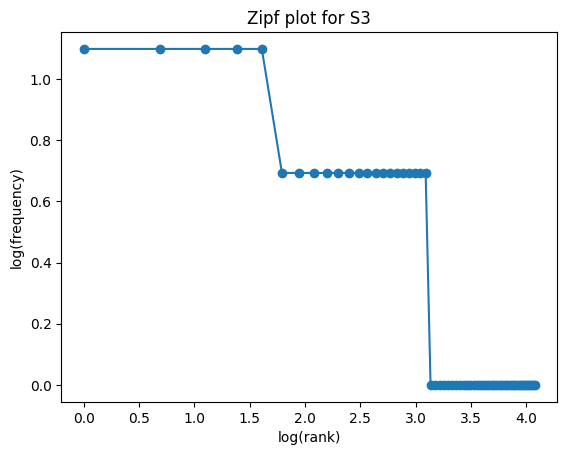

In [16]:
import numpy as np
import matplotlib.pyplot as plt

freq = sorted(Counter(S3).values(), reverse=True)
rank = np.arange(1, len(freq) + 1)

plt.plot(np.log(rank), np.log(freq), "o-")
plt.xlabel("log(rank)")
plt.ylabel("log(frequency)")
plt.title("Zipf plot for S3")
plt.show()

In [17]:
# bigrams taken inside each ticket, not across tickets
b1 = Counter(b for r in res.values() for b in bigrams(r["tokens"]))
b3 = Counter(b for r in res.values() for b in bigrams(r["final"]))
print("Top 5 bigrams S1:", b1.most_common(5))
print("Top 5 bigrams S3:", b3.most_common(5))

Top 5 bigrams S1: [(('.', 'please'), 3), (('please', 'help'), 3), (('help', '.'), 3), (('the', 'vpn'), 2), (('vpn', 'is'), 2)]
Top 5 bigrams S3: [(('please', 'help'), 3), (('showing', 'error'), 2), (('problem', 'occurs'), 2), (('restarting', 'system'), 2), (('stopped', 'responding'), 2)]


**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:* TTR goes 0.489 → 0.549 → 0.686 → 0.640. Going from S1 to S3, we drop the most repeated tokens (`.` appears 23 times and `the` 16 times). So the total falls much faster than the unique count, and TTR rises. Porter then merges forms like worked/working/works → `work`, uploaded/uploading → `upload` and keep/keeps → `keep`. That lowers the unique count (59 → 55) while the total stays at 86, so TTR drops a bit.

---
## Q6. Interpretation

**(a)** S1 → S2 → S3 removes high-frequency, low-content tokens (punctuation, then stopwords), so most of what is removed are repeats. The total drops more than the vocabulary does and TTR rises (0.489 → 0.686). S4 only merges word forms, so the total stays at 86 while the unique count drops, and TTR falls to 0.640.

**(b)** T06 "The printer won't print; it isn't jammed." `word_tokenize` gives `wo`, `n't`, `is`, `n't`, following the Penn Treebank convention of splitting off the negation. My tokenizer keeps `won't` and `isn't` as single tokens, because the word rule `\w+(?:[-']\w+)*` lets an apostrophe sit inside a word.

**(c)** Lancaster stems `error` to `er` and `student` to `stud`. These are not words, and `stud` even means something else. Porter's `please` → `pleas` and `slowly` → `slowli` are also not real words.

**(d)** `printer` (tagged NN) stays `printer` with the lemmatizer, but Lancaster reduces it to `print`, the same as the verb in "won't print". Likewise, `changed` (VBD) becomes the real word `change` with the lemmatizer, while Porter gives `chang`. The POS tag tells the lemmatizer which dictionary form to look up, so the output is always a valid word with the right meaning.